In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
import matplotlib.pyplot as plt
from db import engine

joins = pd.read_sql(
    """
    SELECT m."userId" AS user_id, g."stock
    Id" AS stock_id
    FROM "Membership" m JOIN "Group" g ON g.id = m."groupId"
    WHERE g.type = 'COMMUNITY'
    """,
    engine,
)
stocks = pd.read_sql('SELECT id AS stock_id, symbol, sector FROM "Stock"', engine)

user_ids = joins.user_id.unique()
stock_ids = joins.stock_id.unique()
u_index = {u: i for i, u in enumerate(user_ids)}
s_index = {s: i for i, s in enumerate(stock_ids)}
joins["u"] = joins.user_id.map(u_index)
joins["s"] = joins.stock_id.map(s_index)
n_users, n_stocks = len(user_ids), len(stock_ids)
print(n_users, "users,", n_stocks, "stocks,", len(joins), "joins")

Matplotlib is building the font cache; this may take a moment.


151 users, 67 stocks, 1800 joins


In [2]:
rng = np.random.default_rng(42)
train_rows, test = [], {}

for u, g in joins.groupby("u"):
    items = g.s.values.copy()
    if len(items) < 5:
        train_rows += [(u, s) for s in items]
        continue
    rng.shuffle(items)
    cut = max(1, int(len(items) * 0.2))
    test[u] = set(items[:cut])
    train_rows += [(u, s) for s in items[cut:]]

tr = pd.DataFrame(train_rows, columns=["u", "s"])
X = csr_matrix((np.ones(len(tr)), (tr.u, tr.s)), shape=(n_users, n_stocks))
print("test users:", len(test), "| hidden joins:", sum(len(v) for v in test.values()))

test users: 150 | hidden joins: 300


In [3]:
# 1) Popularity: same list for everyone
pop = np.asarray(X.sum(axis=0)).ravel()

def rec_popularity(u):
    return pop.copy()

# 2) Item-item cosine (what you built before)
sim = cosine_similarity(X.T)
np.fill_diagonal(sim, 0)

def rec_item_item(u):
    return X[u].toarray().ravel() @ sim

# 3) SVD: compress to small vectors ("embeddings"), then rebuild scores
K = 20
svd = TruncatedSVD(n_components=K, random_state=42)
user_vec = svd.fit_transform(X)          # users x K
item_vec = svd.components_                # K x stocks

def rec_svd(u):
    return user_vec[u] @ item_vec

methods = {"popularity": rec_popularity, "item-item": rec_item_item, "SVD": rec_svd}

In [4]:
def evaluate(rec, k=10):
    prec, rec_, n = 0.0, 0.0, 0
    for u, hidden in test.items():
        scores = rec(u).astype(float)
        scores[X[u].indices] = -np.inf          # never recommend training joins
        top = set(np.argsort(scores)[::-1][:k])
        hit = len(top & hidden)
        prec += hit / k
        rec_ += hit / len(hidden)
        n += 1
    return prec / n, rec_ / n

rows = []
for name, fn in methods.items():
    p, r = evaluate(fn, k=10)
    rows.append({"method": name, "precision@10": round(p, 3), "recall@10": round(r, 3)})

results = pd.DataFrame(rows).set_index("method")
results

,precision@10,recall@10
method,,
popularity,0.037,0.174
item-item,0.149,0.757
SVD,0.121,0.637


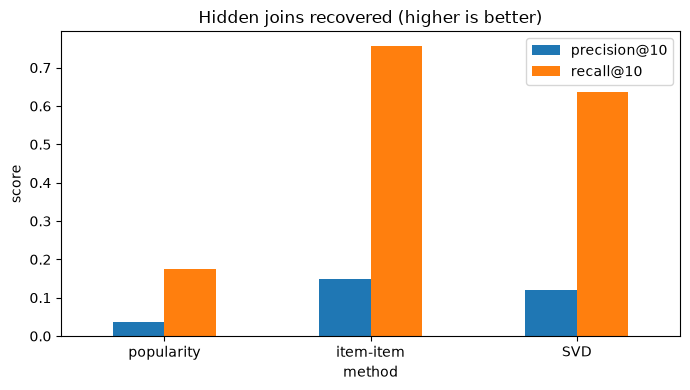

In [5]:
results.plot(kind="bar", figsize=(7, 4), rot=0)
plt.title("Hidden joins recovered (higher is better)")
plt.ylabel("score")
plt.tight_layout()
plt.show()

In [6]:
rows = []
for K in [2, 5, 8, 10, 20, 40]:
    svd = TruncatedSVD(n_components=K, random_state=42)
    uv = svd.fit_transform(X)
    iv = svd.components_
    p, r = evaluate(lambda u: uv[u] @ iv, k=10)
    rows.append({"K": K, "precision@10": round(p, 3), "recall@10": round(r, 3)})
pd.DataFrame(rows).set_index("K")

,precision@10,recall@10
K,,
2,0.062,0.307
5,0.119,0.601
8,0.151,0.769
10,0.142,0.734
20,0.121,0.637
40,0.080,0.423


In [7]:
K_BEST = 8
svd8 = TruncatedSVD(n_components=K_BEST, random_state=42)
uv8 = svd8.fit_transform(X)
iv8 = svd8.components_

def norm(s):
    s = s.astype(float)
    lo, hi = s.min(), s.max()
    return (s - lo) / (hi - lo) if hi > lo else np.zeros_like(s)

def rec_hybrid(u, w=0.5):
    a = norm(X[u].toarray().ravel() @ sim)   # item-item
    b = norm(uv8[u] @ iv8)                    # SVD
    return w * a + (1 - w) * b

rows = []
for name, fn in {
    "item-item": rec_item_item,
    "SVD K=8": lambda u: uv8[u] @ iv8,
    "hybrid 50/50": rec_hybrid,
    "hybrid 70/30": lambda u: rec_hybrid(u, 0.7),
}.items():
    p, r = evaluate(fn, k=10)
    rows.append({"method": name, "precision@10": round(p, 3), "recall@10": round(r, 3)})
pd.DataFrame(rows).set_index("method")

,precision@10,recall@10
method,,
item-item,0.149,0.757
SVD K=8,0.151,0.769
hybrid 50/50,0.149,0.760
hybrid 70/30,0.150,0.762
